# 03 — Preprocessing

Studio Proyek 2 · Klasifikasi 5 jenis sampah (IF25-40401)

Tujuan: menyiapkan data untuk pelatihan berdasarkan temuan `02_eda.ipynb`:
- split train/validasi lokal yang stratified dan **tidak membelah grup duplikat**,
- transform train (augmentasi) dan validasi,
- `ImageFolder` + `DataLoader`.

## 1. Setup

Konstanta sama dengan notebook sebelumnya, ditambah parameter split. Parameter split (`VAL_FRAC = 0.15`, `SEED = 42`, sama dengan `train_baseline.py`) beserta fungsi split dan transform di-import dari `preprocessing.py` (root repo), supaya notebook training 04/05 memakai kode yang sama persis.

In [3]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader
from torchvision import datasets, transforms  # <- ini harus dijalankan SEBELUM import modul proyek


In [4]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))  # supaya preprocessing.py dan submission/ bisa di-import
from preprocessing import (  # tahap preprocessing bersama dengan notebook 04/05
    IMG_SIZE, MEAN, SEED, STD,
    find_duplicate_groups, get_train_transform, get_val_transform, split_by_group, write_split,
    load_files_by_class,
)

In [5]:
DATA_DIR = ROOT / "train"                                # sumber mentah
ADD_DIR = ROOT / "add_train_balance"                     # data tambahan penyeimbang
TRAIN_DIR, VAL_DIR = ROOT / "dataset_sampah" / "my_train", ROOT / "dataset_sampah" / "my_val"
CLASSES = ["botol_plastik", "gelas_plastik", "kertas_kardus", "saset_kemasan", "styrofoam"]
IMG_EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
BATCH_SIZE = 32
NUM_WORKERS = 2  # set 0 kalau DataLoader macet/error di Windows

files_by_class = load_files_by_class(ROOT, CLASSES, IMG_EXTS, extra_dir=ADD_DIR)
all_files = [p for fs in files_by_class.values() for p in fs]
labels = np.array([c for c, fs in files_by_class.items() for _ in fs])
print(f"total gambar: {len(all_files)}")   # harus 3365 (sebelum filter lintas-kelas)

total gambar: 3365


## 2. Kelompokkan near-duplicate

- Temuan EDA: 16 pasangan near-duplicate, 2 di antaranya terbelah di `my_train`/`my_val` lama → skor lokal terlalu optimis.
- Hitung ulang dHash 256-bit (batas jarak 30, sama dengan EDA), lalu gabungkan pasangan menjadi **grup** dengan *union-find*:
  kalau A~B dan B~C, maka A, B, C satu grup walau A dan C tidak terdeteksi langsung.
- Gambar tanpa duplikat menjadi grup berisi dirinya sendiri. Split nanti dilakukan per grup, bukan per gambar.
- Kode dHash + union-find ada di `find_duplicate_groups()` (`preprocessing.py`).

In [6]:
group_id, pairs = find_duplicate_groups(all_files)  # dHash 256-bit + union-find
_, group_sizes = np.unique(group_id, return_counts=True)

print(f"pasangan duplikat     : {len(pairs)}")
print(f"jumlah grup           : {len(group_sizes)} (dari {len(all_files)} gambar)")
print(f"grup berisi > 1 gambar: {(group_sizes > 1).sum()}  | ukuran terbesar: {group_sizes.max()}")
assert all(len(set(labels[group_id == g])) == 1 for g in np.unique(group_id)), "ada grup beda kelas!"
print("OK: setiap grup berisi satu kelas saja")

C:\Users\Revo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\PIL\Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


pasangan duplikat     : 30
jumlah grup           : 3338 (dari 3365 gambar)
grup berisi > 1 gambar: 21  | ukuran terbesar: 3


AssertionError: ada grup beda kelas!

In [7]:
group_id, pairs = find_duplicate_groups(all_files)

# buang grup yang berisi lebih dari satu kelas (tanpa menghapus file)
bad = [g for g in np.unique(group_id) if len(set(labels[group_id == g])) > 1]
keep = ~np.isin(group_id, bad)
print(f"grup lintas-kelas: {len(bad)} | gambar dibuang: {(~keep).sum()}")

all_files = [p for p, k in zip(all_files, keep) if k]
labels = labels[keep]
files_by_class = {c: [p for p, l in zip(all_files, labels) if l == c] for c in CLASSES}

# hitung ulang grup dari data yang sudah bersih
group_id, pairs = find_duplicate_groups(all_files)
_, group_sizes = np.unique(group_id, return_counts=True)
assert all(len(set(labels[group_id == g])) == 1 for g in np.unique(group_id))

grup lintas-kelas: 1 | gambar dibuang: 3


**Temuan:**
- 16 pasangan duplikat → 12 grup (beberapa grup berisi 3 gambar); 2.753 gambar menjadi 2.738 grup.
- Semua grup berisi satu kelas → aman di-split per grup.

## 3. Split stratified per grup

- Per kelas, acak urutan **grup** (bukan gambar), lalu isi `my_val` sampai ±15% gambar kelas itu; sisanya ke `my_train`.
- Satu grup duplikat selalu utuh di satu split → tidak ada kebocoran train/val.
- Folder `my_train/` dan `my_val/` lama (dari `train_baseline.py`) dihapus lalu dibuat ulang. Isinya hanya salinan `train/`, jadi aman.
- Struktur hasilnya `<split>/<kelas>/*.jpg`, langsung bisa dipakai `ImageFolder` dan `evaluate.py --data ./my_val`.
- Logika split ada di `split_by_group()` dan `write_split()` (`preprocessing.py`); notebook 04/05 memanggil fungsi yang sama
  kalau dataset masih berupa `train/` mentah, jadi hasil split-nya identik.

In [11]:
split_of = split_by_group(labels, group_id)  # stratified per kelas, per grup, seed 42
write_split(all_files, labels, split_of, TRAIN_DIR, VAL_DIR)  # hapus lalu tulis ulang my_train/ dan my_val/

# Verifikasi (hitung semua ekstensi gambar, bukan hanya .jpg)
def count_imgs(d):
    return sum(1 for p in d.rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXTS)

print(f"{'kelas':<15} {'train':>6} {'val':>6} {'val %':>6}")
for c in CLASSES:
    n_tr, n_va = count_imgs(TRAIN_DIR / c), count_imgs(VAL_DIR / c)
    print(f"{c:<15} {n_tr:>6} {n_va:>6} {n_va / (n_tr + n_va):>6.1%}")
n_tr_all, n_va_all = count_imgs(TRAIN_DIR), count_imgs(VAL_DIR)
print(f"{'TOTAL':<15} {n_tr_all:>6} {n_va_all:>6}")

split_groups = [g for g in np.unique(group_id) if len({split_of[i] for i in np.where(group_id == g)[0]}) > 1]
assert not split_groups, f"{len(split_groups)} grup duplikat terbelah!"
assert n_tr_all + n_va_all == len(all_files)
print("\nOK: semua gambar tersalin, tidak ada grup duplikat yang terbelah")

kelas            train    val  val %
botol_plastik      571    100  14.9%
gelas_plastik      572    100  14.9%
kertas_kardus      573    100  14.9%
saset_kemasan      573    100  14.9%
styrofoam          573    100  14.9%
TOTAL             2862    500

OK: semua gambar tersalin, tidak ada grup duplikat yang terbelah


**Temuan:**
- Split 2.862 train / 500 val, proporsi val ±14.9% di setiap kelas (stratified terjaga).
- Jumlah per kelas sama dengan split baseline, tapi kini tidak ada grup duplikat yang terbelah → skor `my_val` lebih apa adanya.
- `my_val` kecil (mis. `kertas_kardus` hanya 54 gambar)

## 4. Transform

Berdasarkan temuan EDA:
- **Train (augmentasi):** `RandomResizedCrop` (crop acak 50–100% area, rasio 3:4–4:3) supaya model melihat objek dari berbagai posisi termasuk pinggir gambar lebar;
  flip horizontal; `ColorJitter` agak kuat karena warna terbukti bukan pembeda kelas (EDA cell 6) dan mengurangi ketergantungan pada latar putih katalog.
- **Validasi:** `get_transform()` dari `submission/model.py` (`Resize(256)` + `CenterCrop(224)`), karena harus identik dengan yang dipakai `evaluate.py`.
- Kedua transform ditulis di `preprocessing.py` (root repo), lalu di-import oleh notebook ini dan notebook training 04/05,
  supaya tahap augmentasi tidak ditulis ulang di notebook training. Augmentasi tidak disimpan ke disk: `DataLoader` menerapkannya
  *on-the-fly* saat training, jadi tiap epoch model melihat variasi acak yang berbeda dan `my_train/` tetap berisi gambar asli.
- **Alternatif validasi** `Resize((224, 224))` tanpa crop dipratinjau untuk gambar lebar; dipilih atau tidak diputuskan lewat eksperimen training (perlu mengubah `get_transform()`).

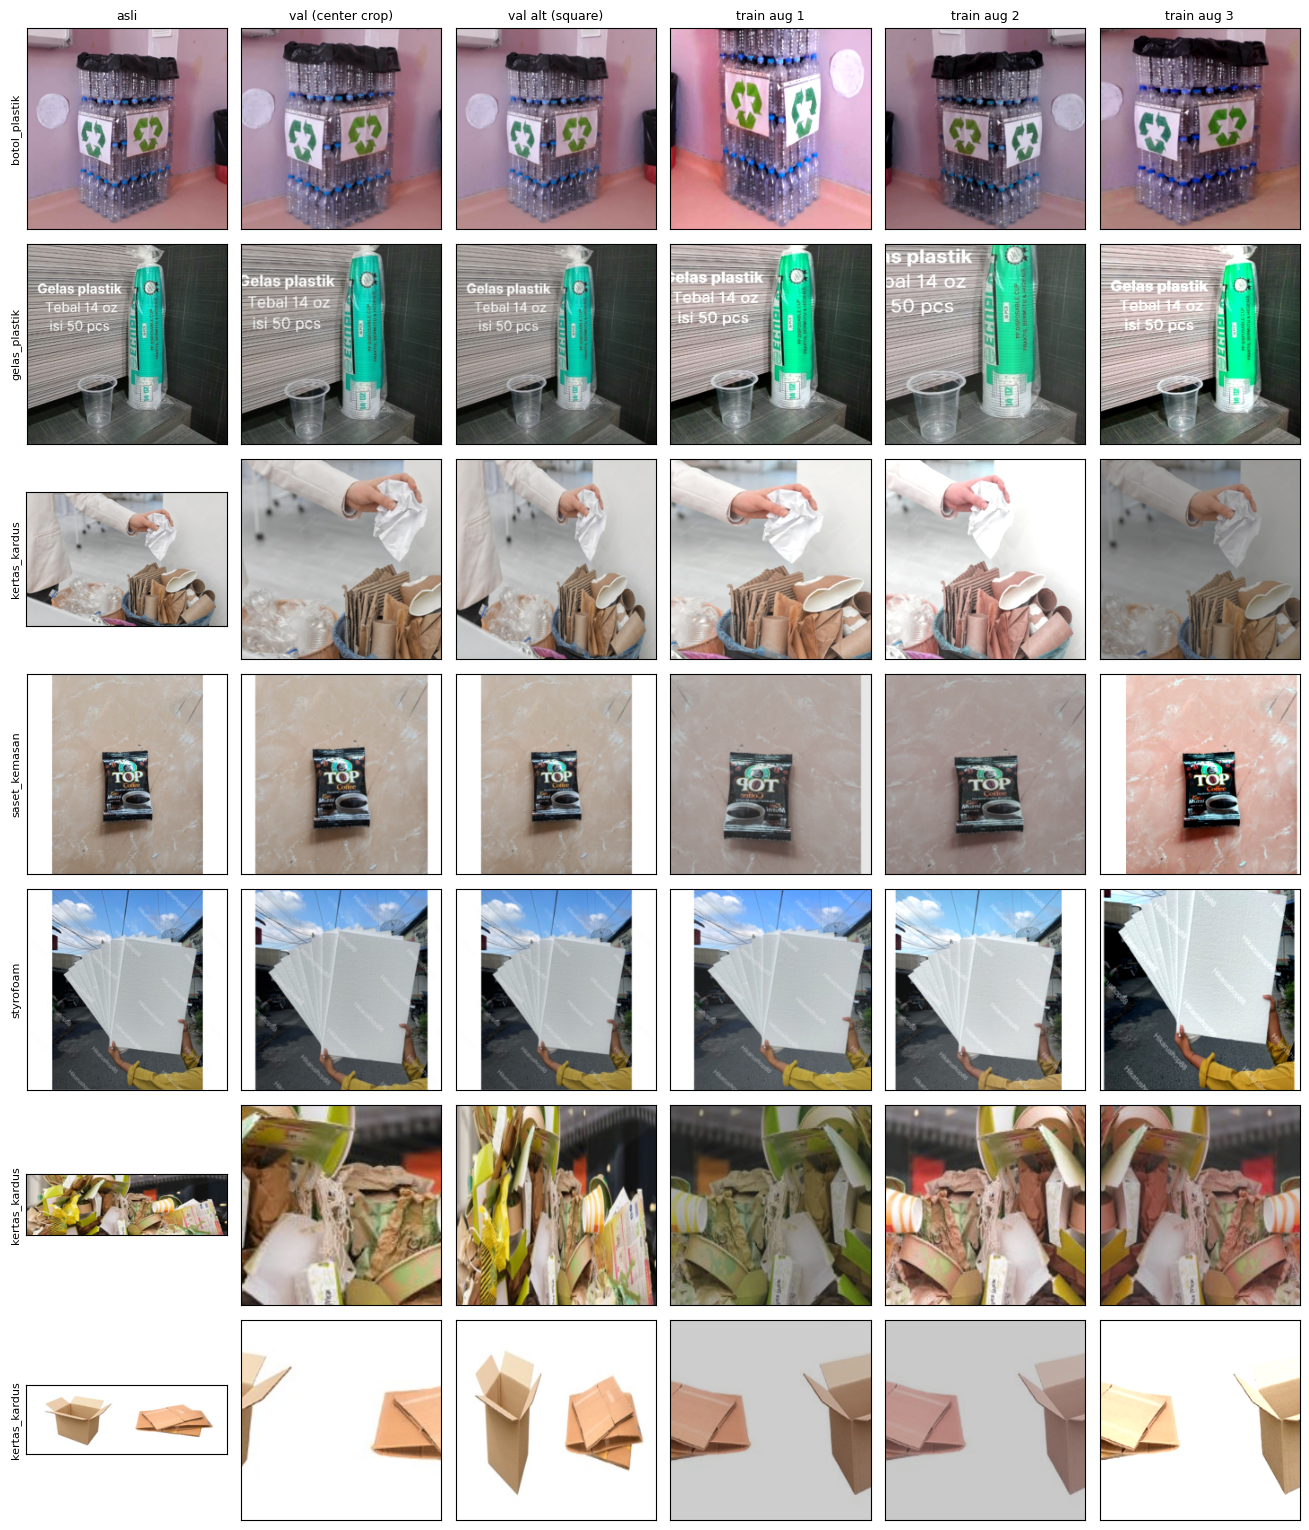

output tensor: (3, 224, 224) torch.float32 | min -0.93 max 2.59


In [13]:
# Didefinisikan di preprocessing.py (dipakai juga oleh notebook 04/05)
train_tf = get_train_transform()
val_tf = get_val_transform()
val_square_tf = transforms.Compose([  # alternatif: tanpa crop, gambar lebar jadi sedikit gepeng
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])


def denorm(x):
    x = x * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]
    return x.clamp(0, 1).permute(1, 2, 0).numpy()


# Pratinjau: 1 gambar per kelas + 2 gambar paling lebar
torch.manual_seed(SEED)
aspects = np.array([Image.open(p).size[0] / Image.open(p).size[1] for p in all_files])
samples = [files_by_class[c][0] for c in CLASSES] + [all_files[i] for i in np.argsort(aspects)[::-1][:2]]
cols = ["asli", "val (center crop)", "val alt (square)", "train aug 1", "train aug 2", "train aug 3"]

fig, axes = plt.subplots(len(samples), len(cols), figsize=(2.2 * len(cols), 2.2 * len(samples)))
for r, p in enumerate(samples):
    with Image.open(p) as im:
        img = im.convert("RGB")
    views = [None, val_tf(img), val_square_tf(img)] + [train_tf(img) for _ in range(3)]
    for col, v in enumerate(views):
        ax = axes[r, col]
        if v is None:
            small = img.copy()
            small.thumbnail((256, 256))
            ax.imshow(small)
            ax.set_ylabel(p.parent.name, fontsize=8)
        else:
            ax.imshow(denorm(v))
        ax.set_xticks([]), ax.set_yticks([])
        if r == 0:
            ax.set_title(cols[col], fontsize=9)
plt.tight_layout()
plt.show()

x = train_tf(img)
print("output tensor:", tuple(x.shape), x.dtype, f"| min {x.min():.2f} max {x.max():.2f}")

**Temuan:**
- Output tensor `(3, 224, 224)` float32, nilai ±-1,8 s/d 2,0 (hasil normalisasi ImageNet) → format sesuai kontrak `get_transform()`.
- Val center crop membuang bagian samping gambar lebar: dus kardus kiri-kanan terpotong separuh, deretan saset hanya tersisa bagian tengah.
- Val alternatif (`Resize` persegi tanpa crop) mempertahankan semua objek; gambar lebar hanya tampak sedikit gepeng. Layak diuji di training.
- Augmentasi train: crop, flip, dan variasi warna terlihat wajar; objek tetap dikenali (satu crop gelas plastik cukup agresif, tapi masih terbaca).
- Teks dan watermark pada gambar katalog tetap terlihat setelah augmentasi → model masih bisa memakainya sebagai shortcut; lewat crop acak membantu mengurangi.

## 5. `ImageFolder` + `DataLoader`

- `ImageFolder` membaca `my_train/` dan `my_val/` (struktur `<split>/<kelas>/*.jpg`) dan memberi label dari nama folder, urut alfabetis → harus sama dengan `CLASSES` (kontrak `evaluate.py`).
- `DataLoader` train diacak (`shuffle=True`), val tidak diacak supaya evaluasi konsisten.
- `pin_memory` aktif hanya kalau ada GPU (CUDA) supaya transfer ke GPU lebih cepat.

In [15]:
device = "cuda" if torch.cuda.is_available() else "cpu"

train_ds = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
val_ds = datasets.ImageFolder(VAL_DIR, transform=val_tf)
assert train_ds.classes == CLASSES == val_ds.classes, "urutan kelas tidak sesuai kontrak submission!"

loader_kwargs = dict(
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=(device == "cuda"),
    persistent_workers=NUM_WORKERS > 0,
)
train_dl = DataLoader(train_ds, shuffle=True, **loader_kwargs)
val_dl = DataLoader(val_ds, shuffle=False, **loader_kwargs)

print("device      :", device)
print("class_to_idx:", train_ds.class_to_idx)
print(f"train: {len(train_ds)} gambar, {len(train_dl)} batch | val: {len(val_ds)} gambar, {len(val_dl)} batch")

device      : cuda
class_to_idx: {'botol_plastik': 0, 'gelas_plastik': 1, 'kertas_kardus': 2, 'saset_kemasan': 3, 'styrofoam': 4}
train: 2862 gambar, 90 batch | val: 500 gambar, 16 batch


**Temuan:**
- `class_to_idx` = `{botol_plastik: 0, gelas_plastik: 1, kertas_kardus: 2, saset_kemasan: 3, styrofoam: 4}` → sesuai kontrak `evaluate.py`.
- Train 2.862 gambar (90 batch), val 500 gambar (16 batch); satu batch berbentuk `(32, 3, 224, 224)` + label `(32,)`.

## 6. Cek satu batch

Ambil satu batch dari `train_dl` dan `val_dl`, tampilkan gambar beserta labelnya untuk memastikan:
- label cocok dengan isi gambar (tidak tertukar antar kelas),
- augmentasi train wajar dan transform val konsisten,
- nilai tensor sudah ternormalisasi.

train: x (32, 3, 224, 224) torch.float32, min -2.12 max 2.64 | label per kelas: {'botol_plastik': 6, 'gelas_plastik': 12, 'kertas_kardus': 6, 'saset_kemasan': 6, 'styrofoam': 2}


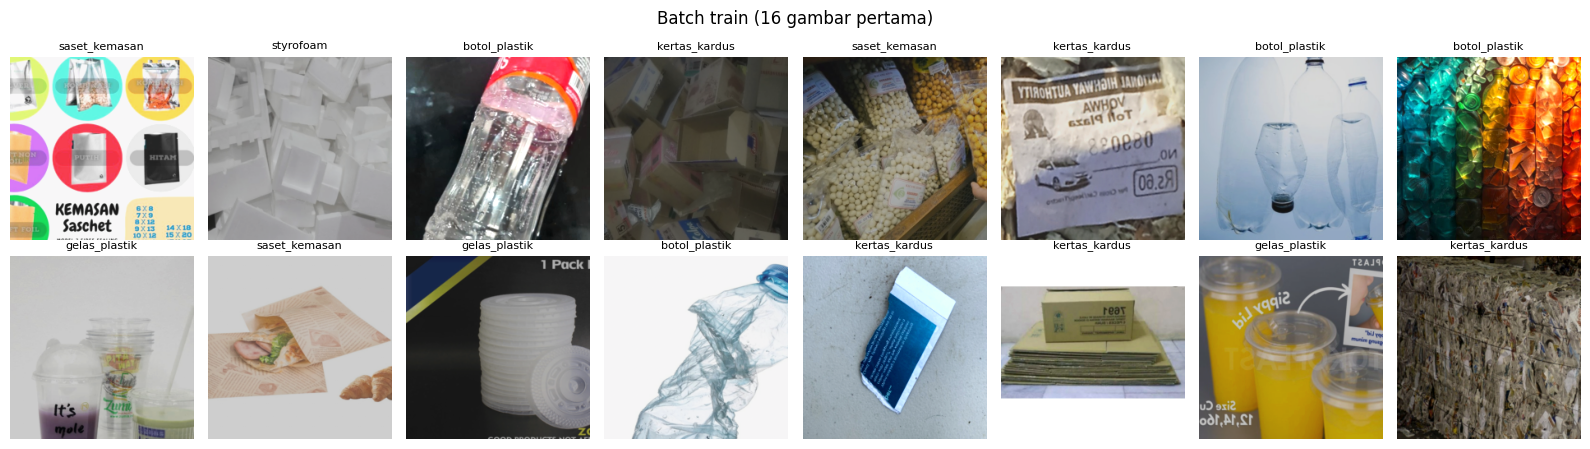

val: x (32, 3, 224, 224) torch.float32, min -2.12 max 2.64 | label per kelas: {'botol_plastik': 32, 'gelas_plastik': 0, 'kertas_kardus': 0, 'saset_kemasan': 0, 'styrofoam': 0}


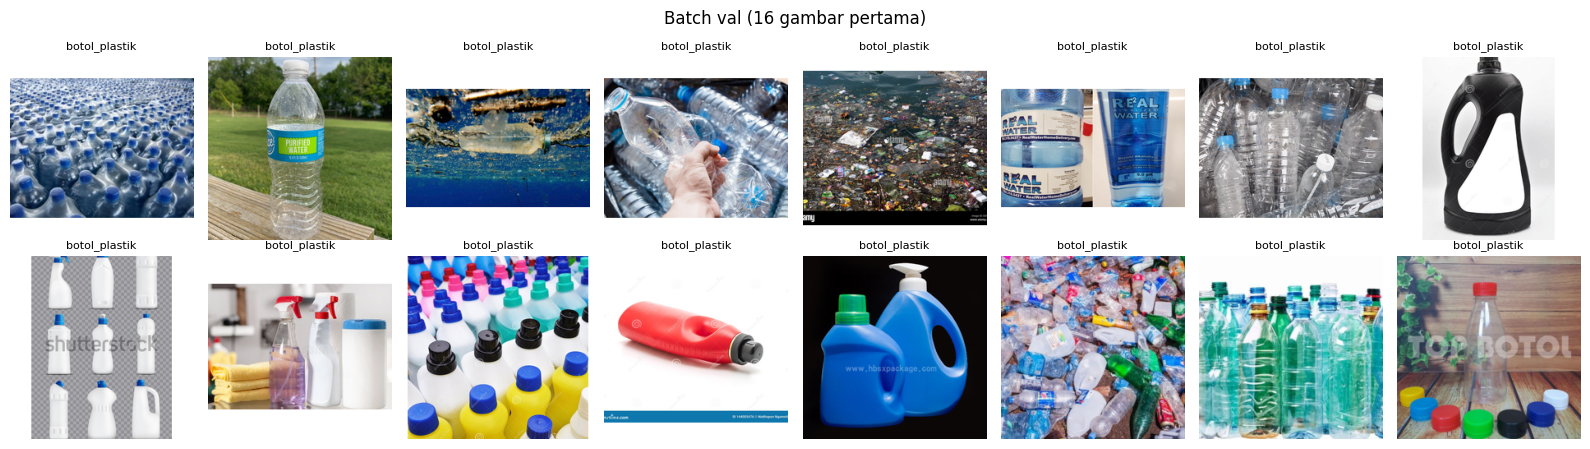

In [16]:
for name, dl in [("train", train_dl), ("val", val_dl)]:
    x, y = next(iter(dl))
    counts_batch = {CLASSES[k]: int((y == k).sum()) for k in range(len(CLASSES))}
    print(f"{name}: x {tuple(x.shape)} {x.dtype}, min {x.min():.2f} max {x.max():.2f} | label per kelas: {counts_batch}")

    fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
    for ax, img, label in zip(axes.flat, x, y):
        ax.imshow(denorm(img))
        ax.set_title(CLASSES[label], fontsize=8)
        ax.axis("off")
    fig.suptitle(f"Batch {name} (16 gambar pertama)")
    plt.tight_layout()
    plt.show()

**Temuan:**
- Nilai tensor min -2,12 / max 2,64 = batas teoretis normalisasi ImageNet (piksel 0 dan 1) → normalisasi benar.
- Batch train berisi campuran kelas (6/8/1/7/10) → `shuffle` bekerja; label cocok dengan isi gambar dan augmentasi terlihat wajar.
- `kertas_kardus` hanya 1 dari 32 gambar di batch ini → kelas minoritas jarang muncul per batch; relevan untuk opsi `WeightedRandomSampler` di training.
- Batch val seluruhnya `botol_plastik` karena `shuffle=False` dan `ImageFolder` urut per kelas → wajar; metrik dihitung atas seluruh val set, jadi tidak berpengaruh.
- Teks yang menyebut kelas masih muncul di gambar (mis. "SACHET ... PLASTIK SASET", "Plastik Teh") → risiko shortcut dari teks tetap ada.
- Ada gambar `botol_plastik` yang isinya tas daur ulang ("TAS GENDONG CIAMIK") → contoh label noise yang disebut di spesifikasi.